# 06. Number of genes kept by strategy s2

The book keeps the top 30 random-forest genes in strategy s2 and does not test any other number. Here the random-forest ranking is fitted once per round on the training patients, then the top 5, 10, 20, 30, 50, 100 and 200 genes are each used to train and score a model.

Splits and seeds are the same as in the baseline, so the 30-gene results repeat the baseline numbers. Two models are used: k-NN with k = 3 and z-scores (the best baseline workflow by accuracy) and the SVM with cost 100 and gamma 0.01 (the book's best workflow).

In [1]:
import sys
sys.path.insert(0, '../src')
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, balanced_accuracy_score, recall_score
from sklearn.model_selection import StratifiedShuffleSplit
from pipeline import anova_genes, load_data, make_models, rf_top_genes

X, y = load_data()
all_models = make_models()
models = {name: all_models[name] for name in ('knn3_z', 'svm_C100_g0.01')}
sizes = [5, 10, 20, 30, 50, 100, 200]

rows = []
for r, (tr, te) in enumerate(StratifiedShuffleSplit(n_splits=100, test_size=0.3, random_state=0).split(X, y)):
    X_train, y_train, true = X.iloc[tr], y.iloc[tr], y.iloc[te]
    s1 = anova_genes(X_train, y_train)
    ranked = rf_top_genes(X_train[s1], y_train, n=max(sizes), seed=r)  # one ranking per round, cut at every size
    for n in sizes:
        for name, model in models.items():
            pred = model.fit(X_train[ranked[:n]], y_train).predict(X.iloc[te][ranked[:n]])
            rows.append({'genes': n, 'model': name, 'accuracy': accuracy_score(true, pred),
                         'balanced_accuracy': balanced_accuracy_score(true, pred),
                         'E2A/PBX1': recall_score(true, pred, labels=['E2A/PBX1'], average=None)[0]})
scores = pd.DataFrame(rows)
scores.to_csv('../results/gene_count_scores.csv', index=False)

## Mean scores by number of genes

In [2]:
summary = scores.groupby(['model', 'genes'])[['accuracy', 'balanced_accuracy', 'E2A/PBX1']].mean()
summary.round(3)

accuracy  balanced_accuracy  E2A/PBX1
model          genes                                       
knn3_z         5         0.719              0.629     0.435
               10        0.797              0.755     0.570
               20        0.841              0.836     0.685
               30        0.852              0.847     0.695
               50        0.861              0.867     0.765
               100       0.864              0.899     0.910
               200       0.853              0.901     0.945
svm_C100_g0.01 5         0.714              0.587     0.415
               10        0.765              0.733     0.575
               20        0.802              0.806     0.680
               30        0.824              0.824     0.670
               50        0.848              0.840     0.675
               100       0.848              0.816     0.595
               200       0.788              0.631     0.100

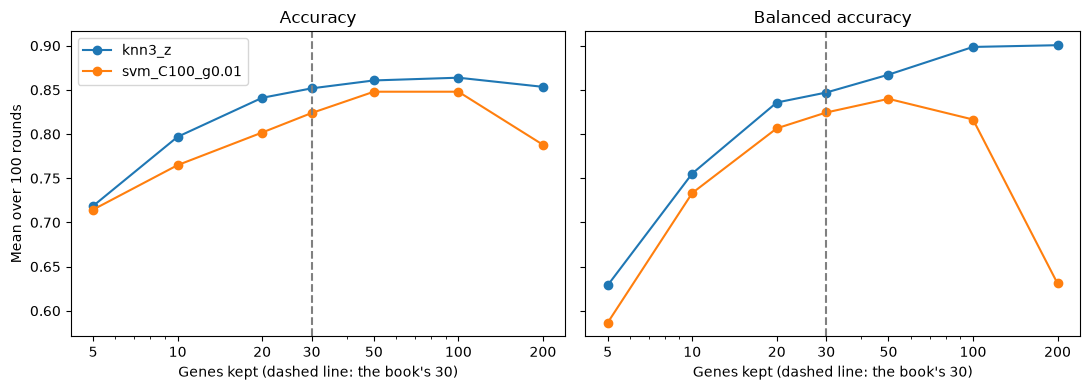

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for i, metric in enumerate(['accuracy', 'balanced_accuracy']):
    for name in models:
        m = summary.loc[name, metric]
        ax[i].plot(m.index, m.values, 'o-', label=name)
    ax[i].axvline(30, ls='--', color='grey')
    ax[i].set_xscale('log')
    ax[i].set_xticks(sizes, sizes)
    ax[i].set_xlabel('Genes kept (dashed line: the book\'s 30)')
    ax[i].set_title(metric.replace('_', ' ').capitalize())
ax[0].set_ylabel('Mean over 100 rounds')
ax[0].legend()
plt.tight_layout()
plt.savefig('../results/gene_count.png', dpi=120)
plt.show()

## Notes

**Result**

- The 30-gene results equal the baseline exactly (`s2_knn3_z` 0.852, `s2_svm_C100_g0.01` 0.824), which confirms that the same splits and rankings are used.
- 30 is not the best number for either model. k-NN keeps improving up to about 100 genes: accuracy 0.864 and balanced accuracy 0.899, against 0.852 and 0.847 at 30. Most of the gain is on E2A/PBX1, whose recall rises from 0.70 to 0.91.
- The SVM peaks at 50 genes (accuracy 0.848, balanced accuracy 0.840) and then falls, to 0.788 accuracy and 0.631 balanced accuracy at 200 genes, with E2A/PBX1 recall down to 0.10. This is the same effect that breaks the s1 SVMs in the baseline: with gamma fixed at 0.01, more genes make the RBF kernel value smaller for every pair of patients, until the model can no longer tell them apart.
- Very small gene sets hurt both models: with 5 genes both drop to about 0.72 accuracy.

**What it means**

- The number of genes and the model interact. The book's choice of 30 is reasonable for both models but not optimal for either, and the right number for the SVM depends on its gamma.
- The best-looking number should not be picked from this table and reported as a result. Choosing it here uses the same test rounds that score it, which is a mild form of the selection bias measured in notebook 03. A fair choice would tune the number of genes inside each training set (nested resampling). The table is a sensitivity study, not a tuned result.

**Limits**

- Two models, one seed, one split scheme. E2A/PBX1 recall rests on 2 test patients per round.